In [9]:
'''>>>>> start CodeP3.2F25
    V.P. Carey ME249, Fall 2025

Intro to Neural Network Modeling 
Keras model for PV power system'''

#import useful packages
import keras
import pandas as pd
from keras.models import Sequential
import numpy as np
import keras.backend as kb
import tensorflow as tf
#the follwoing 2 lines are only needed for Mac OS machines
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

# # define meadian values of input variables - add your values here
# Tamed = 1.  #make sure Tamed does not = 0
# IDmed = 1.
# RLmed = 1.

# #create input data array
# xdata = []

# #Part 1 input data: Air temp (degC), ID (W/sqm), load resistance (ohms)
# xdata = [[-10.0, 350, 4.464]] 
# xdata.append([-10.0, 650, 4.464]) 
# xdata.append([-10.0, 950, 4.464]) 
# xdata.append([-10.0, 1250, 4.464])
# ''' ADD THE REST OF THE INPUT DATA AND CONVERT TO:
# xdata = [[-10.0/Tamed, 350/IDmed, 4.464/RLmed]] 
# xdata.append([-10.0/Tamed, 650/IDmed, 4.464/RLmed]) 
# xdata.append([-10.0/Tamed, 950/IDmed, 4.464/RLmed]) 
# xdata.append([-10.0/Tamed, 1251/IDmed, 4.464/RLmed]) 
# ... etc.'''

# xarray= np.array(xdata)
# print (xdata)
# print (xarray)

# # define meadian values of output variables - add your values here
# VLmed = 1.
# Wdmed = 1

# #create output data array
# ydata = []

# #Part 1 output data: VL (V) and Power out Wd (W)
# ydata = [[18.9, 80.3]] 
# ydata.append([23.5, 124.6]) 
# ydata.append([24.8, 138.6]) 
# ydata.append([25.6, 146.9]) 
# ''' ADD THE REST OF THE OUPUT DATA AND CONVERT TO:
# ydata = [[18.9/VLmed, 80.3/Wdmed]] 
# ydata.append([23.5/VLmed, 124.6/Wdmed]) 
# ydata.append([24.8/VLmed, 138.6/Wdmed]) 
# ydata.append([25.6/VLmed, 146.9/Wdmed]) 
# ... etc.'''

# yarray= np.array(ydata)
# print (ydata)
# print (yarray)




'''>>>>> CodeP3.2F25
    V.P. Carey ME249, Fall 2025
Intro to Neural Network Modeling 
Keras model for PV power system'''

#import useful packages
import keras
import pandas as pd
from keras.models import Sequential
import numpy as np
import keras.backend as kb
import tensorflow as tf

#the following 2 lines are only needed for Mac OS machines
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

# ===== PART 1: Define raw data first, convert temp to Kelvin, then calculate median values =====
# Raw input data: Air temp (degC), ID (W/sqm), load resistance (ohms)
xdata_raw_celsius = [[-10.0, 350, 4.464], 
  [-10.0, 650, 4.464], 
  [-10.0, 950, 4.464], 
  [-10.0, 1250, 4.464], 
  [10.0, 350, 4.464], 
  [10.0, 650, 4.464], 
  [10.0, 950, 4.464], 
  [10.0, 1250, 4.464], 
  [30.0, 350, 4.464], 
  [30.0, 650, 4.464], 
  [30.0, 950, 4.464], 
  [30.0, 1250, 4.466], 
  [-10.0, 350, 6.696], 
  [-10.0, 650, 6.696], 
  [-10.0, 950, 6.696], 
  [-10.0, 1250, 6.696], 
  [10.0, 350, 6.696], 
  [10.0, 650, 6.696], 
  [10.0, 950, 6.696], 
  [10.0, 1250, 6.696], 
  [30.0, 350, 6.696], 
  [30.0, 650, 6.696], 
  [30.0, 950, 6.696], 
  [30.0, 1250, 6.696], 
  [-10.0, 350, 8.928], 
  [-10.0, 650, 8.928], 
  [-10.0, 950, 8.928], 
  [-10.0, 1250, 8.928], 
  [10.0, 350, 8.928], 
  [10.0, 650, 8.928], 
  [10.0, 950, 8.928], 
  [10.0, 1250, 8.928], 
  [30.0, 350, 8.928], 
  [30.0, 650, 8.928], 
  [30.0, 950, 8.928], 
  [30.0, 1250, 8.928]]

# Convert temperature from Celsius to Kelvin (K = degC + 273.15)
xdata_raw = [[row[0] + 273.15, row[1], row[2]] for row in xdata_raw_celsius]

print("===== Temperature Conversion =====")
print("First 3 samples (Celsius -> Kelvin):")
for i in range(3):
    print(f"  {xdata_raw_celsius[i][0]:6.2f} °C  ->  {xdata_raw[i][0]:6.2f} K")
print()

# Raw output data: VL (V) and Power out (W)
ydata_raw = [[18.9, 80.3], 
 [23.5, 124.6], 
 [24.8, 138.6], 
 [25.6, 146.9], 
 [19.2, 83.1], 
 [25.0, 140.5], 
 [26.5, 157.6], 
 [27.3, 167.5],  
 [19.4, 84.7], 
 [26.4, 156.7], 
 [28.1, 177.7], 
 [29.0, 189.4],
 [22.4, 75.2], 
 [24.8, 92.2], 
 [25.8, 99.7], 
 [26.4, 104.6], 
 [23.6, 83.7], 
 [26.5, 104.9], 
 [27.6, 113.8], 
 [28.3, 119.6], 
 [24.8, 92.0], 
 [28.1, 118.2], 
 [29.3, 128.8], 
 [30.1, 135.5],  
 [23.5, 62.2], 
 [25.4, 72.5], 
 [26.3, 77.6], 
 [26.9, 81.1],  
 [25.0, 70.3], 
 [27.1, 82.7], 
 [28.1, 88.7], 
 [28.7, 92.8],  
 [26.5, 78.6], 
 [28.8, 93.5], 
 [29.9, 100.5], 
 [30.6, 105.2]]

# Convert to numpy arrays and calculate medians
xarray_raw = np.array(xdata_raw)
yarray_raw = np.array(ydata_raw)

# Calculate input variable medians from data
Tamed = np.median(xarray_raw[:, 0])   # Air temperature median (K)
IDmed = np.median(xarray_raw[:, 1])   # Irradiance (ID) median (W/sqm)
RLmed = np.median(xarray_raw[:, 2])   # Load resistance median (ohms)

# Calculate output variable medians from data
VLmed = np.median(yarray_raw[:, 0])   # Load voltage (VL) median (V)
Wdmed = np.median(yarray_raw[:, 1])   # Power output (Wd) median (W)

print("===== Calculated Median Values =====")
print(f"Temperature median: {Tamed:.2f} K")
print(f"Irradiance median: {IDmed:.2f} W/sqm")
print(f"Load resistance median: {RLmed:.4f} ohms")
print(f"Voltage median: {VLmed:.2f} V")
print(f"Power median: {Wdmed:.2f} W\n")

# ===== PART 2: Create normalized input data array =====
# Normalize input data by dividing by medians
xdata = []
for row in xdata_raw:
    xdata.append([row[0]/Tamed, row[1]/IDmed, row[2]/RLmed])

xarray = np.array(xdata)
print("===== Normalized Input Data =====")
print("First 5 rows (normalized):")
print(xarray[:5])
print(f"Input shape: {xarray.shape}\n")

# ===== PART 3: Create normalized output data array =====
# Normalize output data by dividing by medians
ydata = []
for row in ydata_raw:
    ydata.append([row[0]/VLmed, row[1]/Wdmed])

yarray = np.array(ydata)
print("===== Normalized Output Data =====")
print("First 5 rows (normalized):")
print(yarray[:5])
print(f"Output shape: {yarray.shape}\n")

# ===== PART 4: Split data into training (2/3) and validation (1/3) sets =====
# Set random seed for reproducibility
np.random.seed(42)

# Generate random indices and shuffle them
total_samples = len(xarray)
indices = np.arange(total_samples)
np.random.shuffle(indices)

# Calculate split point (2/3 for training, 1/3 for validation)
split_point = int(2/3 * total_samples)

# Split indices
train_indices = indices[:split_point]
val_indices = indices[split_point:]

# Create training and validation sets
x_train = xarray[train_indices]
y_train = yarray[train_indices]
x_val = xarray[val_indices]
y_val = yarray[val_indices]

print("===== Data Split =====")
print(f"Total samples: {total_samples}")
print(f"Training set size: {len(x_train)} ({len(x_train)/total_samples*100:.1f}%)")
print(f"Validation set size: {len(x_val)} ({len(x_val)/total_samples*100:.1f}%)")
print(f"\nTraining input shape: {x_train.shape}")
print(f"Training output shape: {y_train.shape}")
print(f"Validation input shape: {x_val.shape}")
print(f"Validation output shape: {y_val.shape}\n")



===== Temperature Conversion =====
First 3 samples (Celsius -> Kelvin):
  -10.00 °C  ->  263.15 K
  -10.00 °C  ->  263.15 K
  -10.00 °C  ->  263.15 K

===== Calculated Median Values =====
Temperature median: 283.15 K
Irradiance median: 800.00 W/sqm
Load resistance median: 6.6960 ohms
Voltage median: 26.45 V
Power median: 100.10 W

===== Normalized Input Data =====
First 5 rows (normalized):
[[0.92936606 0.4375     0.66666667]
 [0.92936606 0.8125     0.66666667]
 [0.92936606 1.1875     0.66666667]
 [0.92936606 1.5625     0.66666667]
 [1.         0.4375     0.66666667]]
Input shape: (36, 3)

===== Normalized Output Data =====
First 5 rows (normalized):
[[0.71455577 0.8021978 ]
 [0.88846881 1.24475524]
 [0.93761815 1.38461538]
 [0.96786389 1.46753247]
 [0.72589792 0.83016983]]
Output shape: (36, 2)

===== Data Split =====
Total samples: 36
Training set size: 24 (66.7%)
Validation set size: 12 (33.3%)

Training input shape: (24, 3)
Training output shape: (24, 2)
Validation input shape: (12

In [2]:
# define neural network model

#As seen below, we have created four dense layers. 
#A dense layer is a layer in neural network that’s fully connected. 
#In other words, all the neurons in one layer are connected to all other neurons in the next layer.
#In the first layer, we need to provide the input shape, which is 1 in our case. 
#The activation function we have chosen is elu, which stands for exponential linear unit. .

from keras import backend as K
#initialize weights with values between -0.2 and 0.5
# initializer = keras.initializers.RandomUniform(minval= -0.2, maxval=0.5)
initializer = keras.initializers.RandomUniform(minval= -0.2, maxval=0.5)

model = keras.Sequential([
    keras.layers.Dense(6, activation='elu', input_shape=[3],  kernel_initializer=initializer),
    keras.layers.Dense(12, activation='elu',  kernel_initializer=initializer),
    keras.layers.Dense(6, activation='elu', kernel_initializer=initializer),
    keras.layers.Dense(2,  kernel_initializer=initializer)
  ])


/global/home/users/melius/.conda/envs/my_kernel/lib/python3.11/site-packages/keras/src/layers/core/dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-11-25 14:39:25.217971: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:266] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [10]:
#We’re using RMSprop as our optimizer here. RMSprop stands for Root Mean Square Propagation. 
#It’s one of the most popular gradient descent optimization algorithms for deep learning networks. 
#RMSprop is an optimizer that’s reliable and fast.
#We’re compiling the mode using the model.compile function. The loss function used here 
#is mean squared error. After the compilation of the model, we’ll use the fit method with ~500 epochs.
#Number of epochs can be varied.

#from tf.keras import optimizers
# rms = keras.optimizers.RMSprop(0.020)
rms = keras.optimizers.RMSprop(0.02)
model.compile(loss='mse',optimizer=rms)


In [11]:
#After the compilation of the model, we’ll use the fit method with 500 epochs.
#I started with epochs value of 100 and then tested the model after training. 
#The prediction was not that good. Then I modified the number of epochs to 200 and tested the model again. 
#Accuracy had improved slightly, but figured I’d give it one more try. Finally, at 500 epochs 
#I found acceptable prediction accuracy.

#The fit method takes three parameters; namely, x, y, and number of epochs. 
#During model training, if all the batches of data are seen by the model once, 
#we say that one epoch has been completed.

# Add an early stopping callback
es = keras.callbacks.EarlyStopping(
    monitor='loss', 
    mode='min', 
    patience = 80, 
    restore_best_weights = True, 
    verbose=1)
# Add a checkpoint where loss is minimum, and save that model
mc = keras.callbacks.ModelCheckpoint('best_model.keras', monitor='loss', 
                     mode='min',  verbose=1, save_best_only=True)

# historyData = model.fit(x_train,y_train,epochs=800,callbacks=[es])
historyData = model.fit(xarray,yarray,epochs=6000)

loss_hist = historyData.history['loss']
#The above line will return a dictionary, access it's info like this:
best_epoch = np.argmin(historyData.history['loss']) + 1
print ('best epoch = ', best_epoch)
print('smallest loss =', np.min(loss_hist))

model.save('./best_model.keras')

Epoch 1/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.1010 
Epoch 2/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0769
Epoch 3/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0211
Epoch 4/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0115
Epoch 5/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0078
Epoch 6/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0086
Epoch 7/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0042
Epoch 8/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0049
Epoch 9/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0038
Epoch 10/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0037
Epoch 11/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0063
Epoch 12/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0049
Epoch 13/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0026
Epoch 14/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0039
Epoch 15/6000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0075
Epo

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [12]:


# This line of code can be used to reconstruct the saved model.

recon_model = keras.models.load_model("best_model.keras")

# the name of the model is now "recon_model". You can then use this model to do predictions for comparisons.
# See the previous project for code to do the comparisons.








2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
row [0] data:  T1=  263.15 , ID=  350.0 , RL=  4.464 , power=  80.3 ,  predicted power =  79.18213180303573
row [1] data:  T1=  263.15 , ID=  650.0 , RL=  4.464 , power=  124.6 ,  predicted power =  122.38099343776702
row [2] data:  T1=  263.15 , ID=  950.0 , RL=  4.464 , power=  138.6 ,  predicted power =  135.15746001005172
row [3] data:  T1=  263.15 , ID=  1250.0 , RL=  4.464 , power=  146.9 ,  predicted power =  143.2596144914627
row [4] data:  T1=  283.15 , ID=  350.0 , RL=  4.464 , power=  83.1 ,  predicted power =  80.15500512123107
row [5] data:  T1=  283.15 , ID=  650.0 , RL=  4.464 , power=  140.5 ,  predicted power =  140.07896108627318
row [6] data:  T1=  283.15 , ID=  950.0 , RL=  4.464 , power=  157.6 ,  predicted power =  155.62782247066497
row [7] data:  T1=  283.15 , ID=  1250.0 , RL=  4.464 , power=  167.5 ,  predicted power =  163.46677408218383
row [8] data:  T1=  303.15 , ID=  350.0 , RL=  4.464 , power=  84.7 ,  predicted powe

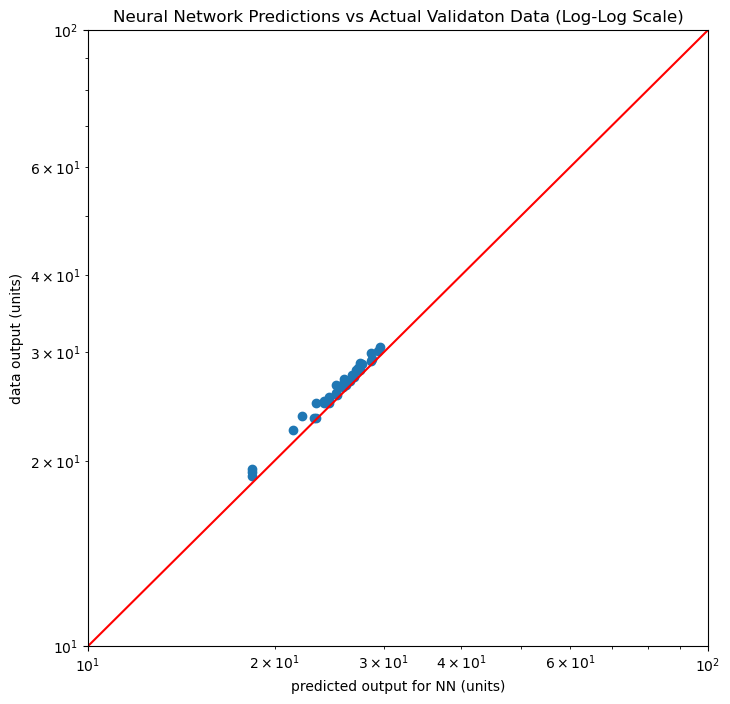

In [13]:
test = []
outpt=[]
predictions = model.predict(xarray)

#put in a loop to print comparison for all data points
for i in range(len(xarray)):
    test = [[xarray[i][0], xarray[i][1], xarray[i][2]]]
    testarray = np.array(test)
    outpt = model.predict(testarray, verbose=0)
    print('row [' + str(i) + '] data:  T1= ', xarray[i][0]*Tamed, ', ID= ', xarray[i][1]*IDmed, \
        ', RL= ', xarray[i][2]*RLmed, ', power= ', yarray[i][1]*Wdmed, \
        ',  predicted power = ', outpt[0][1]*Wdmed)

#SETTING UP PLOT
%matplotlib inline
# importing the required module
import matplotlib.pyplot as plt 
plt.rcParams['figure.figsize'] = [8, 8] # for square canvas 
#========
'''CALCULATE PREDICTED VALUES AND RETRIEVE DATA VALUES TO PLOT'''
# Denormalize for plotting
predictions_denorm = predictions[:, 0] * VLmed
actual_denorm = yarray[:, 0] * VLmed

plt.scatter(predictions_denorm, actual_denorm)
plt.title('Neural Network Predictions vs Actual Validaton Data (Log-Log Scale)')
plt.xlabel('predicted output for NN (units)') 
plt.ylabel('data output (units)')
plt.loglog()
plt.xlim(xmax=100, xmin=10)
plt.ylim(ymax=100, ymin=10)
# Generate red y=x line using logspace for proper log scale
x_data = np.logspace(np.log10(1.0), np.log10(100.0), num=100)
y_data = x_data
plt.plot(x_data, y_data, color='red')
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
row [0] data:  T1=  0.9293660603920184 , ID=  0.4375 , RL=  0.6666666666666667 , power=  80.3 ,  predicted power =  104.16374396085739
row [1] data:  T1=  0.9293660603920184 , ID=  0.8125 , RL=  0.6666666666666667 , power=  124.6 ,  predicted power =  90.0057874917984
row [2] data:  T1=  0.9293660603920184 , ID=  1.1875 , RL=  0.6666666666666667 , power=  138.6 ,  predicted power =  79.00411754846573
row [3] data:  T1=  0.9293660603920184 , ID=  1.5625 , RL=  0.6666666666666667 , power=  146.9 ,  predicted power =  87.48456723690032
row [4] data:  T1=  1.0 , ID=  0.4375 , RL=  0.6666666666666667 , power=  83.1 ,  predicted power =  77.45113469958305
row [5] data:  T1=  1.0 , ID=  0.8125 , RL=  0.6666666666666667 , power=  140.5 ,  predicted power =  91.5864784181118
row [6] data:  T1=  1.0 , ID=  1.1875 , RL=  0.6666666666666667 , power=  157.6 ,  predicted power =  116.1954694390297
row [7] data:  T1=  1.0 , ID=  1.5625 , RL=  0.6666666666666667 ,

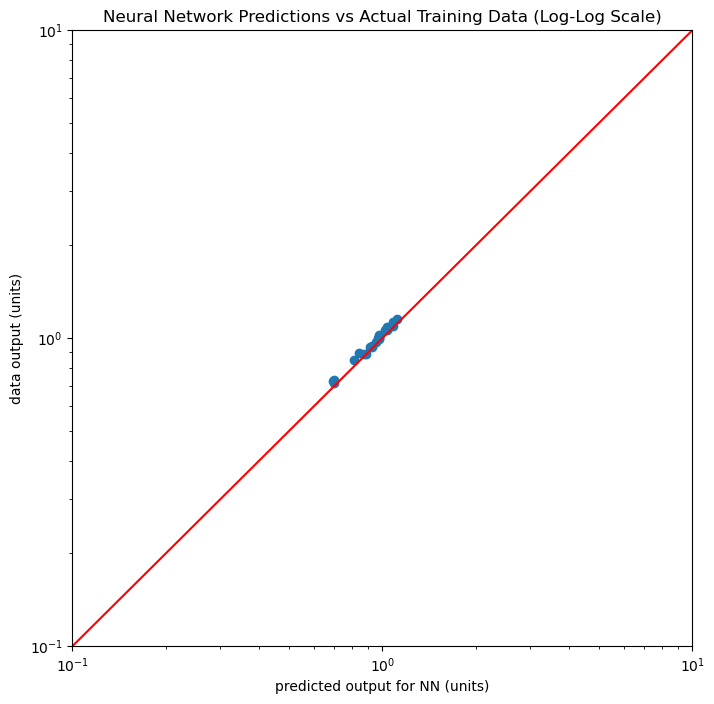

In [14]:
test = []
outpt=[]
predictions = model.predict(x_train)

#put in a loop to print comparison for all data points
for i in range(len(x_train)):
    test = [[x_train[i][0], x_train[i][1], x_train[i][2]]]
    testarray = np.array(test)
    outpt = model.predict(testarray, verbose=0)
    print('row [' + str(i) + '] data:  T1= ', xarray[i][0], ', ID= ', xarray[i][1], \
        ', RL= ', xarray[i][2], ', power= ', yarray[i][1]*Wdmed, \
        ',  predicted power = ', outpt[0][1]*Wdmed)

#SETTING UP PLOT
%matplotlib inline
# importing the required module
import matplotlib.pyplot as plt 
plt.rcParams['figure.figsize'] = [8, 8] # for square canvas 
#========
'''CALCULATE PREDICTED VALUES AND RETRIEVE DATA VALUES TO PLOT'''
# Denormalize for plotting
predictions_denorm = predictions[:, 0] 
actual_denorm = y_train[:, 0] 

plt.scatter(predictions_denorm, actual_denorm)
plt.title('Neural Network Predictions vs Actual Training Data (Log-Log Scale)')
plt.xlabel('predicted output for NN (units)') 
plt.ylabel('data output (units)')
plt.loglog()
plt.xlim(xmax=10, xmin=0.1)
plt.ylim(ymax=10, ymin=0.1)
# Generate red y=x line using logspace for proper log scale
x_data = np.logspace(np.log10(0.1), np.log10(10.0), num=100)
y_data = x_data
plt.plot(x_data, y_data, color='red')
plt.show()

===== Fixed Parameters =====
Air Temperature: 20.0°C = 293.15 K
===== Input Ranges =====
Load Resistance (RL): 4.0 - 8.0 Ohms (20 points)
Irradiance (ID): 500.0 - 1200.0 W/m² (20 points)
Total predictions: 400

===== Normalized Input Statistics =====
Temperature (normalized): 1.0353
Irradiance (normalized): min=0.6250, max=1.5000
Load Resistance (normalized): min=0.5974, max=1.1947

===== Power Output Statistics =====
Minimum Power: 85.73 W
Maximum Power: 182.68 W
Mean Power: 128.59 W



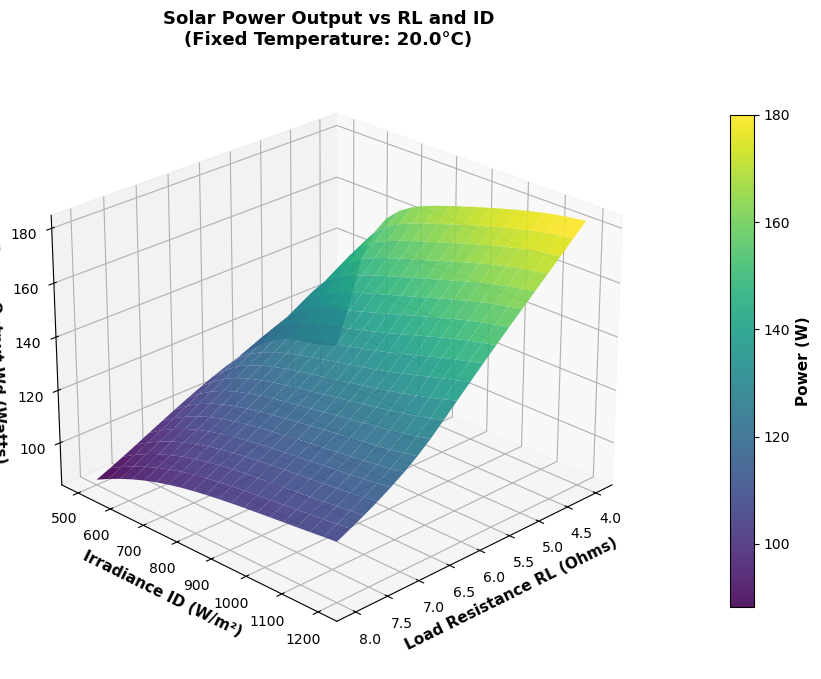

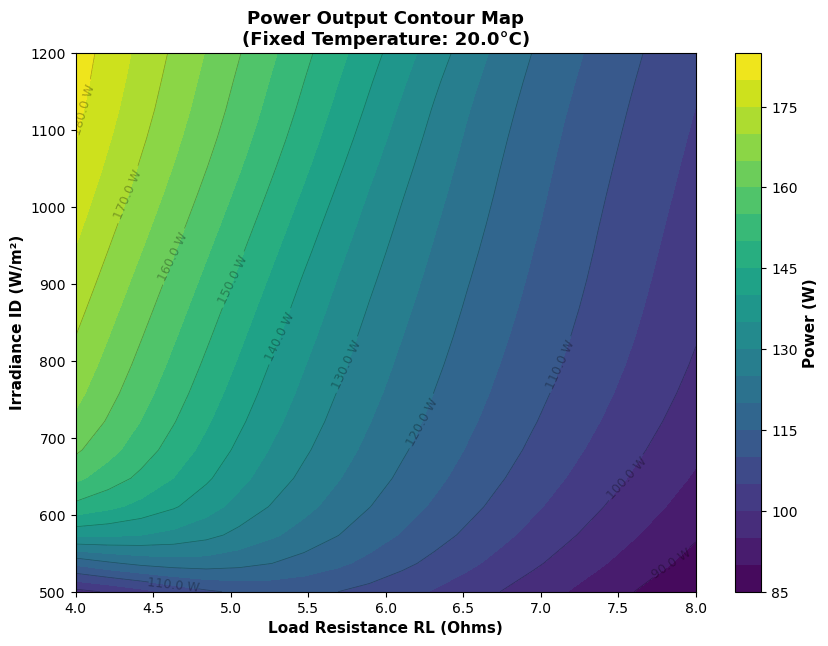

===== Sample Predictions =====

RL = 4.00 Ω, ID = 500 W/m², Power = 98.42 W
RL = 8.00 Ω, ID = 500 W/m², Power = 85.73 W
RL = 4.00 Ω, ID = 868 W/m², Power = 171.63 W
RL = 8.00 Ω, ID = 1200 W/m², Power = 106.05 W

===== Optimal Load Resistance for Maximum Power =====

ID (W/m²)  |  Optimal RL (Ω)  |  Max Power (W)
--------------------------------------------------
   500     |       5.26      |      111.45
   647     |       4.00      |      156.07
   795     |       4.00      |      168.26
   942     |       4.00      |      174.74
  1089     |       4.00      |      180.12


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# ===== FIXED PARAMETER =====
T_fixed_celsius = 20.0  # Fixed air temperature in Celsius
T_fixed_kelvin = T_fixed_celsius + 273.15  # Convert to Kelvin

print("===== Fixed Parameters =====")
print(f"Air Temperature: {T_fixed_celsius}°C = {T_fixed_kelvin:.2f} K")

# ===== CREATE GRID FOR PREDICTIONS =====
# Load resistance range: 4 to 8 Ohms
RL_min, RL_max = 4.0, 8.0
RL_points = 20  # Number of points in RL direction

# Irradiance range: 500 to 1200 W/m^2
ID_min, ID_max = 500.0, 1200.0
ID_points = 20  # Number of points in ID direction

# Create meshgrid
RL_array = np.linspace(RL_min, RL_max, RL_points)
ID_array = np.linspace(ID_min, ID_max, ID_points)
RL_mesh, ID_mesh = np.meshgrid(RL_array, ID_array)

print("===== Input Ranges =====")
print(f"Load Resistance (RL): {RL_min} - {RL_max} Ohms ({RL_points} points)")
print(f"Irradiance (ID): {ID_min} - {ID_max} W/m² ({ID_points} points)")
print(f"Total predictions: {RL_points * ID_points}\n")

# ===== NORMALIZE INPUT DATA FOR MODEL =====
# Flatten meshgrid for model prediction
RL_flat = RL_mesh.flatten()
ID_flat = ID_mesh.flatten()
# Fill with fixed Kelvin temperature
T_flat = np.full_like(RL_flat, T_fixed_kelvin)

# Normalize by medians (same way as training)
RL_norm = RL_flat / RLmed
ID_norm = ID_flat / IDmed
T_norm = T_flat / Tamed

# Create input array [T, ID, RL] for the model
input_data = np.column_stack([T_norm, ID_norm, RL_norm])

print("===== Normalized Input Statistics =====")
print(f"Temperature (normalized): {T_norm[0]:.4f}")
print(f"Irradiance (normalized): min={ID_norm.min():.4f}, max={ID_norm.max():.4f}")
print(f"Load Resistance (normalized): min={RL_norm.min():.4f}, max={RL_norm.max():.4f}\n")

# ===== GET PREDICTIONS FROM MODEL =====
predictions_normalized = model.predict(input_data, verbose=0)

# Extract power output (second column) and denormalize
power_normalized = predictions_normalized[:, 1]  # Column 1 is power output
power_denorm = power_normalized * Wdmed  # Denormalize using median

# Reshape back to grid
power_grid = power_denorm.reshape(RL_mesh.shape)

print("===== Power Output Statistics =====")
print(f"Minimum Power: {power_grid.min():.2f} W")
print(f"Maximum Power: {power_grid.max():.2f} W")
print(f"Mean Power: {power_grid.mean():.2f} W\n")

# ===== CREATE 3D SURFACE PLOT =====
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Create surface plot
surf = ax.plot_surface(RL_mesh, ID_mesh, power_grid, cmap='viridis', 
                       edgecolor='none', alpha=0.9, antialiased=True)

# Labels and title
ax.set_xlabel('Load Resistance RL (Ohms)', fontsize=11, fontweight='bold')
ax.set_ylabel('Irradiance ID (W/m²)', fontsize=11, fontweight='bold')
ax.set_zlabel('Power Output Wd (Watts)', fontsize=11, fontweight='bold')
ax.set_title(f'Solar Power Output vs RL and ID\n(Fixed Temperature: {T_fixed_celsius}°C)', 
             fontsize=13, fontweight='bold')

# Add colorbar
cbar = fig.colorbar(surf, ax=ax, pad=0.1, shrink=0.8)
cbar.set_label('Power (W)', fontsize=11, fontweight='bold')

# Adjust viewing angle for better visualization
ax.view_init(elev=25, azim=45)

plt.savefig("surface_plot.png", dpi=300, bbox_inches='tight')
plt.show()

# ===== CREATE CONTOUR PLOT =====
fig, ax = plt.subplots(figsize=(10, 7))

# Create filled contour plot
contourf = ax.contourf(RL_mesh, ID_mesh, power_grid, levels=20, cmap='viridis')
contour = ax.contour(RL_mesh, ID_mesh, power_grid, levels=10, colors='black', 
                     alpha=0.3, linewidths=0.5)

# Add contour labels
ax.clabel(contour, inline=True, fontsize=9, fmt='%.1f W')

# Labels and title
ax.set_xlabel('Load Resistance RL (Ohms)', fontsize=11, fontweight='bold')
ax.set_ylabel('Irradiance ID (W/m²)', fontsize=11, fontweight='bold')
ax.set_title(f'Power Output Contour Map\n(Fixed Temperature: {T_fixed_celsius}°C)', 
             fontsize=13, fontweight='bold')

# Add colorbar
cbar = fig.colorbar(contourf, ax=ax)
cbar.set_label('Power (W)', fontsize=11, fontweight='bold')
plt.savefig("Contour_plot.png", dpi=300, bbox_inches='tight')

plt.show()

# ===== PRINT SAMPLE PREDICTIONS =====
print("===== Sample Predictions =====\n")
sample_indices = [0, RL_points-1, RL_points*ID_points//2, RL_points*ID_points-1]
for idx in sample_indices:
    if idx < len(RL_flat):
        print(f"RL = {RL_flat[idx]:.2f} Ω, ID = {ID_flat[idx]:.0f} W/m², Power = {power_denorm[idx]:.2f} W")

# ===== OPTIONAL: Find optimal RL for maximum power at each ID =====
print("\n===== Optimal Load Resistance for Maximum Power =====\n")
print("ID (W/m²)  |  Optimal RL (Ω)  |  Max Power (W)")
print("-" * 50)
for j in range(0, ID_points, ID_points//5):
    max_power_idx = np.argmax(power_grid[j, :])
    optimal_rl = RL_array[max_power_idx]
    max_power = power_grid[j, max_power_idx]
    print(f"{ID_array[j]:6.0f}     |     {optimal_rl:6.2f}      |     {max_power:7.2f}")
